# CODE 5.2: Where the Models Look and What They Miss

> **Goal:** look closer at the test results of notebook 5.1, for PatchCore and YOLO.
>
> 1. When a model gives REJECT to a defect photo, does it point at the real defect?
> 2. What do the missed defect photos look like, and what did the two models see on them?
> 3. What made some good photos get REJECT by mistake?
>
> - **Input:**
>   - `results/evaluation/test_decisions.csv` and `score_limits.csv`: the limits and decisions of notebook 5.1
>   - `results/patchcore/split_1_scores.csv` and `split_1_patch_scores.npz` (and 2, 3): PatchCore's most unusual patch and the patch distances for the heatmaps (notebook 4.1)
>   - `results/yolo/split_1_scores.csv` and `split_1_boxes.csv` (and 2, 3): YOLO's most confident box and its other boxes (notebook 4.3)
>   - the crops and the true boxes of notebooks 3.1 and 3.2
> - **Output:** nothing is saved. This notebook only looks.
>
> The limits and the decisions are taken from notebook 5.1 and are not changed here.

### How the Pointing Check Works

> Each model has one place on the photo that it finds most suspicious:
>
> - **PatchCore:** the patch with the highest distance, which is the reddest spot of the heatmap. Its centre is the model's **point**.
> - **YOLO:** its most confident box. The centre of that box is the model's point.
>
> The model **points at the defect** if its point lies inside a true box (the boxes of notebook 3.2, made from the masks), or less than one patch (16 pixels) away from one.
>
> This matters most for the defect photos a model catches. A REJECT that points somewhere else is right for the wrong reason: the photo has a defect, but the model reacted to something else. A missed photo can still point at the defect: then the model looked at the right place but was not sure enough.

### Words Used in This Notebook

> - **Point:** the centre of the place a model finds most suspicious (above).
> - **True box:** a box around a real defect, made from the mask in notebook 3.2. White and dashed in the figures.
> - **Heatmap colours** in this notebook: dark blue is the typical distance of a normal patch, and red is PatchCore's limit from notebook 5.1. So a red spot alone is enough for REJECT.
> - **Miss** and **false reject:** as in notebook 5.1, a defect photo that gets PASS, and a good photo that gets REJECT.

## Import Libraries & Variables

### Import Libraries

> - The first line saves figures as JPEG, so the notebook file stays small.
> - `os`: works with folders and file paths.
> - `numpy`, `pandas`: work with numbers and tables.
> - `matplotlib`: draws the figures. `Rectangle` draws the boxes.
> - `PIL` (Pillow): opens the crops.
> - `scipy.ndimage`, `torch`: make the heatmaps exactly as in notebook 4.1. Everything runs on the CPU; no GPU is needed.

In [1]:
%config InlineBackend.figure_formats = ["jpeg"]

import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from scipy import ndimage
import torch
import torch.nn.functional as F

### Variables

#### Folder Paths

> This code finds the main project folder. It starts in the folder of this notebook and goes up until it finds the `data` folder, so the paths work wherever the notebook is.
>
> - `CROP_DIR`: the crops (notebook 3.1). `TRUE_BOX_FILE`: the true boxes, with the defect type of every box (notebook 3.2).
> - `PATCHCORE_DIR`, `YOLO_DIR`: the scores of notebooks 4.1 and 4.3.
> - `EVALUATION_DIR`: the limits and decisions of notebook 5.1.
>
> If notebook 5.1 has not been run, the code stops with a message that says what to do.

In [2]:
ROOT_DIR = os.getcwd()
while not os.path.isdir(os.path.join(ROOT_DIR, "data")) and ROOT_DIR != os.path.dirname(ROOT_DIR):
    ROOT_DIR = os.path.dirname(ROOT_DIR)

CROP_DIR = os.path.join(ROOT_DIR, "data", "processed", "crops")
TRUE_BOX_FILE = os.path.join(CROP_DIR, "yolo_boxes.csv")
PATCHCORE_DIR = os.path.join(ROOT_DIR, "results", "patchcore")
YOLO_DIR = os.path.join(ROOT_DIR, "results", "yolo")
EVALUATION_DIR = os.path.join(ROOT_DIR, "results", "evaluation")

if not os.path.exists(os.path.join(EVALUATION_DIR, "test_decisions.csv")):
    raise FileNotFoundError("results/evaluation/test_decisions.csv not found. Run notebook 5.1 first.")
print("Project folder found:", os.path.basename(ROOT_DIR))

Project folder found: visual-defect-inspection


#### Settings

> - `SPLITS`, `MODELS`: the 3 splits and the 5 models of every split, as in notebook 5.1.
> - `SHOWN_K`, `SHOWN_MODEL`: the YOLO model drawn in the figures. YOLO with k = 40 is the one that caught up with PatchCore in notebook 5.1, so the figures compare the two equally good models. The pointing check (Step 1) still covers every k.
> - `HEATMAP_SIGMA`: the blur of the heatmap, 8 pixels, the same as in notebook 4.1 (4 pixels at half size).
> - `FALSE_REJECTS_SHOWN`: how many false rejects per model Step 3 draws, the ones with the highest score compared with their limit.
> - `WRONG_REASON_SHOWN`: at most this many photos per model in the figure of Step 1 (caught, but pointing somewhere else).

In [3]:
SPLITS = [1, 2, 3]
MODELS = ["PatchCore", "YOLO k = 5", "YOLO k = 10", "YOLO k = 20", "YOLO k = 40"]
SHOWN_K = 40
SHOWN_MODEL = f"YOLO k = {SHOWN_K}"
HEATMAP_SIGMA = 8
FALSE_REJECTS_SHOWN = 2
WRONG_REASON_SHOWN = 2

## Functions

### Paths and Names

> - `full_path()` turns a path from a table, written with `/`, into a real path on this computer (as in the earlier notebooks).
> - `short_name()` shortens a path for titles: `chewinggum/Data/Images/Anomaly/042.JPG` becomes `Anomaly/042`.

In [4]:
def full_path(base_dir, rel_path):
    return os.path.join(base_dir, *rel_path.split("/"))


def short_name(rel_path):
    return os.path.splitext("/".join(rel_path.split("/")[-2:]))[0]

### Does the Point Lie on a Defect?

> `points_at_defect()` gets a point (`x`, `y` in crop pixels) and the true boxes of the photo. Every box is made `margin` pixels bigger on every side. The answer is True if the point lies inside at least one of these bigger boxes. A normal photo has no true boxes, so the answer is always False.

In [5]:
def points_at_defect(x, y, boxes, margin):
    return any(left - margin <= x <= right + margin and top - margin <= y <= bottom + margin
               for left, top, right, bottom in boxes)

### From Patch Grid to Heatmap

> `grid_to_heatmap()` is the same function as in notebook 4.1: it stretches the grid of patch distances to the size of the crop (`interpolate`, `bilinear`) and smooths it with a Gaussian blur of `sigma` pixels.

In [6]:
def grid_to_heatmap(grid, crop_size, sigma):
    grid_tensor = torch.from_numpy(np.asarray(grid, dtype=np.float32))[None, None]
    stretched = F.interpolate(grid_tensor, size=(crop_size[1], crop_size[0]), mode="bilinear", align_corners=False)
    return ndimage.gaussian_filter(stretched[0, 0].numpy(), sigma=sigma)

### Draw the True Boxes

> `draw_true_boxes()` draws the true boxes of a photo: white, dashed.

In [7]:
def draw_true_boxes(ax, boxes):
    for left, top, right, bottom in boxes:
        ax.add_patch(Rectangle((left, top), right - left, bottom - top, fill=False, edgecolor="white",
                               linewidth=1.5, linestyle="--"))

### Draw What PatchCore Sees

> `show_patchcore()` draws the crop with PatchCore's heatmap on top (half transparent, from dark blue at `vmin` to red at `vmax`), the true boxes, and PatchCore's point as a white cross.

In [8]:
def show_patchcore(ax, crop, heatmap, boxes, vmin, vmax, point):
    ax.imshow(crop)
    ax.imshow(heatmap, cmap="jet", alpha=0.45, vmin=vmin, vmax=vmax)
    draw_true_boxes(ax, boxes)
    ax.plot(point[0], point[1], marker="x", color="white", markersize=14, markeredgewidth=3)
    ax.axis("off")

### Draw What YOLO Sees

> `show_yolo()` draws the crop, the true boxes and YOLO's own boxes:
>
> - every YOLO box with a confidence above the limit, in red, with its confidence written above it,
> - if no box is above the limit (PASS), only the most confident box, in yellow.
>
> `boxes` must be sorted from the most to the least confident box, as in the boxes file of notebook 4.3.

In [9]:
def show_yolo(ax, crop, true_boxes, boxes, limit):
    ax.imshow(crop)
    draw_true_boxes(ax, true_boxes)
    above = boxes[boxes["confidence"] > limit]
    shown, color = (above, "red") if len(above) else (boxes.head(1), "yellow")
    for _, box in shown.iterrows():
        ax.add_patch(Rectangle((box["left"], box["top"]), box["right"] - box["left"], box["bottom"] - box["top"],
                               fill=False, edgecolor=color, linewidth=2))
        ax.text(box["left"], box["top"] - 8, f"{box['confidence']:.3g}", color=color, fontsize=9, fontweight="bold")
    ax.axis("off")

### Draw One Photo, Both Models

> `show_photo_row()` fills one row of three pictures for one test photo of one split, using the tables loaded below:
>
> 1. the photo with its true boxes, and its defect types (or "normal") in the title,
> 2. what PatchCore of that split sees,
> 3. what YOLO (`SHOWN_MODEL`) of that split sees.
>
> The titles give each model's score, its limit and its decision.

In [10]:
def show_photo_row(axes, s, image):
    crop_image = crop_image_of[image]
    crop = np.asarray(Image.open(full_path(CROP_DIR, crop_image)).convert("RGB"))
    boxes = true_boxes.get(crop_image, [])
    patchcore = decision_table.loc[(s, "PatchCore", image)]
    yolo = decision_table.loc[(s, SHOWN_MODEL, image)]

    axes[0].imshow(crop)
    draw_true_boxes(axes[0], boxes)
    axes[0].set_title(f"split {s}: {short_name(image)}\n{patchcore['defect_types'].replace(',', ', ') or 'normal'}", fontsize=10)
    axes[0].axis("off")

    heatmap = grid_to_heatmap(grids[s][grid_row[s][image]], crop_size=CROP_SIZE, sigma=HEATMAP_SIGMA)
    show_patchcore(axes[1], crop, heatmap, boxes, vmin=heat_low[s], vmax=patchcore["limit"], point=patchcore_point[(s, image)])
    axes[1].set_title(f"PatchCore: {patchcore['score']:.3g} (limit {patchcore['limit']:.3g}) "
                      f"{'REJECT' if patchcore['rejected'] else 'PASS'}", fontsize=10)

    yolo_photo_boxes = shown_boxes[s][shown_boxes[s]["crop_image"] == crop_image]
    show_yolo(axes[2], crop, boxes, yolo_photo_boxes, yolo["limit"])
    axes[2].set_title(f"{SHOWN_MODEL}: {yolo['score']:.3g} (limit {yolo['limit']:.3g}) "
                      f"{'REJECT' if yolo['rejected'] else 'PASS'}", fontsize=10)

## Load Data

### The Decisions of Notebook 5.1 and the True Boxes

> - `decisions`: every test photo of every split and model, with its score, limit and decision (`rejected`). `decision_table` is the same table, so that one row can be found by split, model and photo.
> - `crop_image_of`: the crop of every photo.
> - `true_boxes`: the true boxes of every defect crop, in crop pixels (left, top, right, bottom).
> - `CROP_SIZE`: the size of every crop.

In [11]:
decisions = pd.read_csv(os.path.join(EVALUATION_DIR, "test_decisions.csv")).fillna({"defect_types": ""})
decision_table = decisions.set_index(["split", "model", "image"]).sort_index()
crop_image_of = dict(zip(decisions["image"], decisions["crop_image"]))

box_table = pd.read_csv(TRUE_BOX_FILE)
true_boxes = {crop_image: list(zip(rows["left"], rows["top"], rows["right"], rows["bottom"]))
              for crop_image, rows in box_table.groupby("crop_image")}
CROP_SIZE = Image.open(full_path(CROP_DIR, decisions["crop_image"].iloc[0])).size

print(f"Decisions: {len(decisions)} rows, for {decisions['image'].nunique()} different test photos")
print(f"True boxes: {len(box_table)} boxes in {len(true_boxes)} defect crops")
print(f"Crop size: {CROP_SIZE[0]} x {CROP_SIZE[1]} pixels")

Decisions: 2250 rows, for 322 different test photos
True boxes: 205 boxes in 100 defect crops
Crop size: 928 x 608 pixels


### PatchCore's Patches and YOLO's Boxes

> For every split:
>
> - `grids[s]`: the patch distances of every validation and test photo (notebook 4.1), and `grid_row[s]`: which row of `grids[s]` belongs to which photo.
> - `PATCH_PIXELS`: how many crop pixels one patch stands for, from the size of the grid.
> - `heat_low[s]`: the typical distance of a normal patch, the median of all patch distances of the normal validation photos (as in notebook 4.1). It is the dark blue end of the heatmap colours; the red end is PatchCore's limit of the split.
> - `patchcore_scores[s]`: PatchCore's score table, with the grid row and column of its most unusual patch (`best_row`, `best_col`).
> - `yolo_scores[s]`: YOLO's score table, with the corners of its most confident box (`best_left` and so on), for every k.
> - `shown_boxes[s]`: all boxes of `SHOWN_MODEL`, sorted from the most confident one, to draw them.

In [12]:
grids, grid_row, heat_low, patchcore_scores, yolo_scores, shown_boxes = {}, {}, {}, {}, {}, {}
for s in SPLITS:
    with np.load(os.path.join(PATCHCORE_DIR, f"split_{s}_patch_scores.npz")) as patch_file:
        grids[s] = patch_file["grids"]
        grid_row[s] = {image: row for row, image in enumerate(patch_file["images"])}
    patchcore_scores[s] = pd.read_csv(os.path.join(PATCHCORE_DIR, f"split_{s}_scores.csv"))
    normal_val = patchcore_scores[s][(patchcore_scores[s]["part"] == "val") & ~patchcore_scores[s]["is_defect"]]
    heat_low[s] = float(np.median(grids[s][[grid_row[s][image] for image in normal_val["image"]]]))
    yolo_scores[s] = pd.read_csv(os.path.join(YOLO_DIR, f"split_{s}_scores.csv"))
    boxes = pd.read_csv(os.path.join(YOLO_DIR, f"split_{s}_boxes.csv"))
    shown_boxes[s] = boxes[boxes["k"] == SHOWN_K].sort_values("confidence", ascending=False)

PATCH_PIXELS = CROP_SIZE[0] // grids[1].shape[2]
print(f"Patch grid: {grids[1].shape[1]} rows x {grids[1].shape[2]} columns, one patch = {PATCH_PIXELS} x {PATCH_PIXELS} crop pixels")
for s in SPLITS:
    print(f"Split {s}: heatmap colours from {heat_low[s]:.3g} (dark blue) to the limit (red)")

Patch grid: 38 rows x 58 columns, one patch = 16 x 16 crop pixels
Split 1: heatmap colours from 1.55 (dark blue) to the limit (red)
Split 2: heatmap colours from 1.54 (dark blue) to the limit (red)
Split 3: heatmap colours from 1.55 (dark blue) to the limit (red)


> **What we see:** the grid has 38 x 58 patches of 16 x 16 crop pixels, as in notebook 4.1. A typical normal patch has a distance of about 1.55 in every split, and PatchCore's limits are about 2.1 (notebook 5.1). So in the heatmaps, red means much more unusual than a typical patch of good gum.

## Step 1: Does the Model Point at the Defect?

### The Point of Every Model on Every Defect Test Photo

> For every split, every model and every defect test photo:
>
> - PatchCore's point is the centre of its most unusual patch: `(best_col + 0.5) * PATCH_PIXELS` from the left and `(best_row + 0.5) * PATCH_PIXELS` from the top.
> - YOLO's point is the centre of its most confident box: halfway between `best_left` and `best_right`, and between `best_top` and `best_bottom`.
> - `on the defect`: `points_at_defect()` with a margin of one patch (`PATCH_PIXELS`).
> - `rejected`: the decision of notebook 5.1.
>
> `patchcore_point` keeps PatchCore's point of every test photo (also the normal ones), for the figures.

In [13]:
point_rows, patchcore_point = [], {}
for s in SPLITS:
    test = patchcore_scores[s][patchcore_scores[s]["part"] == "test"]
    for image, row, col, is_defect in zip(test["image"], test["best_row"], test["best_col"], test["is_defect"]):
        patchcore_point[(s, image)] = ((col + 0.5) * PATCH_PIXELS, (row + 0.5) * PATCH_PIXELS)
        if is_defect:
            point_rows.append({"split": s, "model": "PatchCore", "image": image,
                               "x": patchcore_point[(s, image)][0], "y": patchcore_point[(s, image)][1]})
    test = yolo_scores[s][(yolo_scores[s]["part"] == "test") & yolo_scores[s]["is_defect"]]
    for _, photo in test.iterrows():
        point_rows.append({"split": s, "model": f"YOLO k = {int(photo['k'])}", "image": photo["image"],
                           "x": (photo["best_left"] + photo["best_right"]) / 2, "y": (photo["best_top"] + photo["best_bottom"]) / 2})

points = pd.DataFrame(point_rows).merge(decisions[["split", "model", "image", "crop_image", "defect_types", "rejected"]],
                                        on=["split", "model", "image"])
points["on the defect"] = [points_at_defect(x, y, true_boxes.get(crop_image, []), PATCH_PIXELS)
                           for x, y, crop_image in zip(points["x"], points["y"], points["crop_image"])]
print(f"Points: {len(points)} | defect test rows in notebook 5.1: {decisions['is_defect'].sum()}")
points.head()

Points: 750 | defect test rows in notebook 5.1: 750


,split,model,image,x,y,crop_image,defect_types,rejected,on the defect
0,1,PatchCore,chewinggum/Data/Images/Anomaly/000.JPG,264.0,296.0,images/Anomaly/000.png,"chunk of gum missing,scratches,small cracks",True,True
1,1,PatchCore,chewinggum/Data/Images/Anomaly/001.JPG,360.0,152.0,images/Anomaly/001.png,"corner missing,small cracks",True,True
2,1,PatchCore,chewinggum/Data/Images/Anomaly/003.JPG,504.0,472.0,images/Anomaly/003.png,"corner missing,small cracks",True,True
3,1,PatchCore,chewinggum/Data/Images/Anomaly/006.JPG,488.0,264.0,images/Anomaly/006.png,"chunk of gum missing,small cracks",True,True
4,1,PatchCore,chewinggum/Data/Images/Anomaly/007.JPG,328.0,392.0,images/Anomaly/007.png,"chunk of gum missing,corner missing,small cracks",True,True


### How Often the Point Lies on the Defect

> For every model, over the 3 splits together, the defect test photos split into four groups: caught or missed, and pointing at the defect or somewhere else. The last column is the share of the caught photos where the model points at the defect.
>
> The caught photos (the first two count columns together) must be the same as in notebook 5.1: this is checked below the table.

In [14]:
groups = {"caught, on the defect": points["rejected"] & points["on the defect"],
          "caught, elsewhere": points["rejected"] & ~points["on the defect"],
          "missed, on the defect": ~points["rejected"] & points["on the defect"],
          "missed, elsewhere": ~points["rejected"] & ~points["on the defect"]}
pointing = pd.DataFrame({name: points[chosen].groupby("model").size() for name, chosen in groups.items()})
pointing = pointing.reindex(MODELS).fillna(0).astype(int)
caught = pointing["caught, on the defect"] + pointing["caught, elsewhere"]
pointing["on the defect (% of caught)"] = (100 * pointing["caught, on the defect"] / caught).round(1)

results_51 = pd.read_csv(os.path.join(EVALUATION_DIR, "test_results.csv"))
print("Caught photos as in notebook 5.1:", caught.to_dict() == results_51.groupby("model")["caught"].sum().reindex(MODELS).to_dict())
pointing

Caught photos as in notebook 5.1: True


,"caught, on the defect","caught, elsewhere","missed, on the defect","missed, elsewhere",on the defect (% of caught)
model,,,,,
PatchCore,143,3,0,4,97.9
YOLO k = 5,119,6,4,21,95.2
YOLO k = 10,133,4,5,8,97.1
YOLO k = 20,136,3,5,6,97.8
YOLO k = 40,145,2,1,2,98.6


> **What we see:**
>
> - There are 750 points, one per model and defect test photo, as many as the defect test rows of notebook 5.1, and the caught photos are the same as there (True).
> - **When a model catches a defect photo, it almost always points at the real defect:** PatchCore in 143 of its 146 caught photos (97.9%), YOLO in 95.2% (k = 5) to 98.6% (k = 40). So a person can check a REJECT of either model by looking at the place it marks.
> - **The missed photos mostly point somewhere else:** PatchCore's point lies away from the defect in all 4 of its misses, so it did not see these defects at all. YOLO with k = 5 points somewhere else in 21 of its 25 misses, and with k = 40 in 2 of its 3.
> - A missed photo that points at the defect means: right place, but not sure enough. This happens 0 times for PatchCore and 1 to 5 times for YOLO.

### Caught, but Pointing Somewhere Else

> At most `WRONG_REASON_SHOWN` photos per model: defect photos that PatchCore or YOLO (`SHOWN_MODEL`) caught while pointing somewhere else. Each row shows one photo, with both models. The white cross is PatchCore's point; for YOLO, the red boxes are above its limit.

Caught but pointing elsewhere: PatchCore 3, YOLO k = 40 2


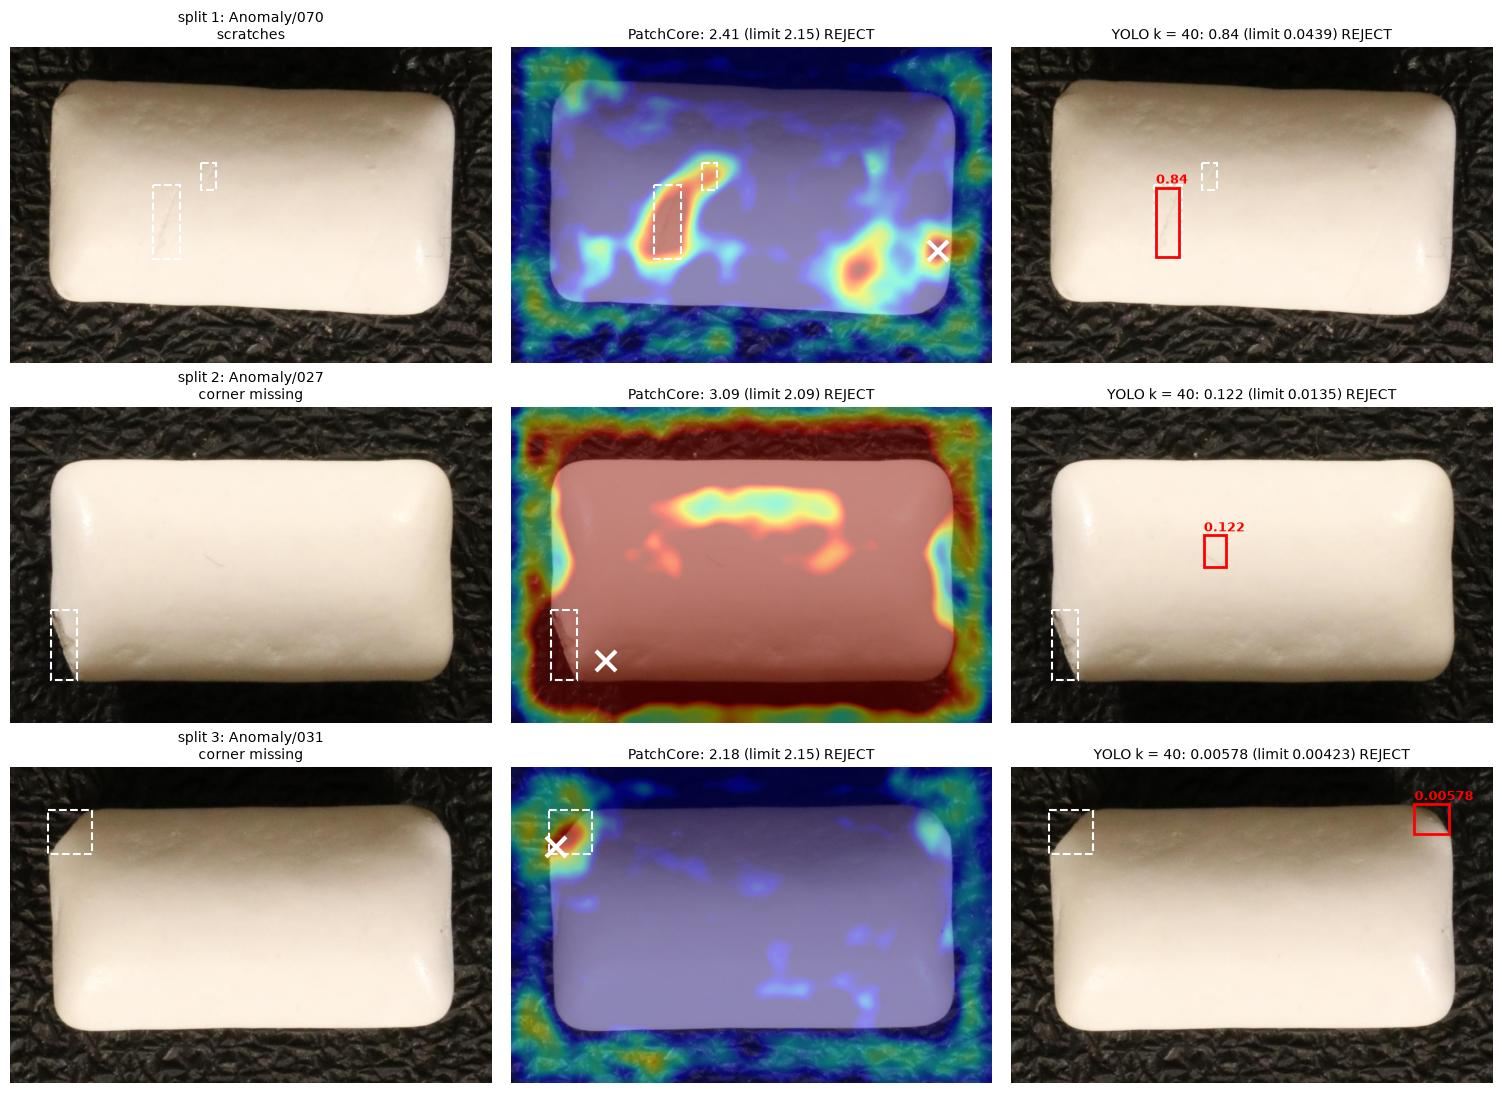

In [15]:
wrong_reason = points[points["model"].isin(["PatchCore", SHOWN_MODEL]) & points["rejected"] & ~points["on the defect"]]
shown = wrong_reason.groupby("model").head(WRONG_REASON_SHOWN)[["split", "image"]].drop_duplicates()
print(f"Caught but pointing elsewhere: PatchCore {(wrong_reason['model'] == 'PatchCore').sum()}, "
      f"{SHOWN_MODEL} {(wrong_reason['model'] == SHOWN_MODEL).sum()}")

if len(shown):
    fig, axes = plt.subplots(len(shown), 3, figsize=(15, 3.6 * len(shown)), layout="constrained", squeeze=False)
    for ax_row, (s, image) in zip(axes, shown.itertuples(index=False)):
        show_photo_row(ax_row, s, image)
    plt.show()

> **What we see** (PatchCore has 3 such photos and YOLO with k = 40 has 2; the figure shows at most 2 per model):
>
> - **Anomaly/070** (split 1, scratches): PatchCore's heatmap is red on the scratch too, but its reddest spot is at the right edge of the gum, so its point counts as somewhere else. YOLO's box lies on the scratch (0.84).
> - **Anomaly/027** (split 2, corner missing): PatchCore's heatmap is red almost everywhere, so to PatchCore the whole photo looks unusual (score 3.09), and its point lies just next to the missing corner. YOLO's box lies in the middle of the gum, not on the corner.
> - **Anomaly/031** (split 3, corner missing): PatchCore points at the missing corner. YOLO gives REJECT because of a weak box on the other top corner (0.00578, just above its very low limit of 0.00423): right for the wrong reason.

## Step 2: The Missed Defect Photos

### Which Photos Were Missed

> Every defect test photo that PatchCore or YOLO (`SHOWN_MODEL`) missed, in any split. The same photo can be a test photo in more than one split; it is then listed once per split, because every split has its own models. The table shows both models' decisions and whether their point lies on the defect.

In [16]:
pair_models = ["PatchCore", SHOWN_MODEL]
missed = points[points["model"].isin(pair_models) & ~points["rejected"]][["split", "image"]].drop_duplicates()
missed = missed.sort_values(["split", "image"]).reset_index(drop=True)

missed_table = missed.copy()
missed_table["photo"] = missed_table["image"].map(short_name)
missed_table["defect types"] = [decision_table.loc[(s, "PatchCore", image), "defect_types"] for s, image in zip(missed["split"], missed["image"])]
point_of = points.set_index(["split", "model", "image"]).sort_index()
for model in pair_models:
    missed_table[f"{model}: decision"] = ["REJECT" if decision_table.loc[(s, model, image), "rejected"] else "PASS"
                                          for s, image in zip(missed["split"], missed["image"])]
    missed_table[f"{model}: on the defect"] = [point_of.loc[(s, model, image), "on the defect"]
                                               for s, image in zip(missed["split"], missed["image"])]
missed_table.drop(columns="image")

,split,photo,defect types,PatchCore: decision,PatchCore: on the defect,YOLO k = 40: decision,YOLO k = 40: on the defect
0,1,Anomaly/026,corner missing,REJECT,True,PASS,False
1,1,Anomaly/032,"corner missing,scratches",PASS,False,REJECT,True
2,1,Anomaly/039,corner missing,REJECT,True,PASS,True
3,2,Anomaly/031,corner missing,REJECT,True,PASS,False
4,2,Anomaly/032,"corner missing,scratches",PASS,False,REJECT,True
5,3,Anomaly/032,"corner missing,scratches",PASS,False,REJECT,True
6,3,Anomaly/033,corner missing,PASS,False,REJECT,True


### What the Two Models See on Them

> One row per missed photo: the photo with its true boxes, PatchCore's heatmap and point, and YOLO's boxes. Red on the heatmap means as unusual as the limit or more; for YOLO, a yellow box means its most confident box is still below the limit (PASS).

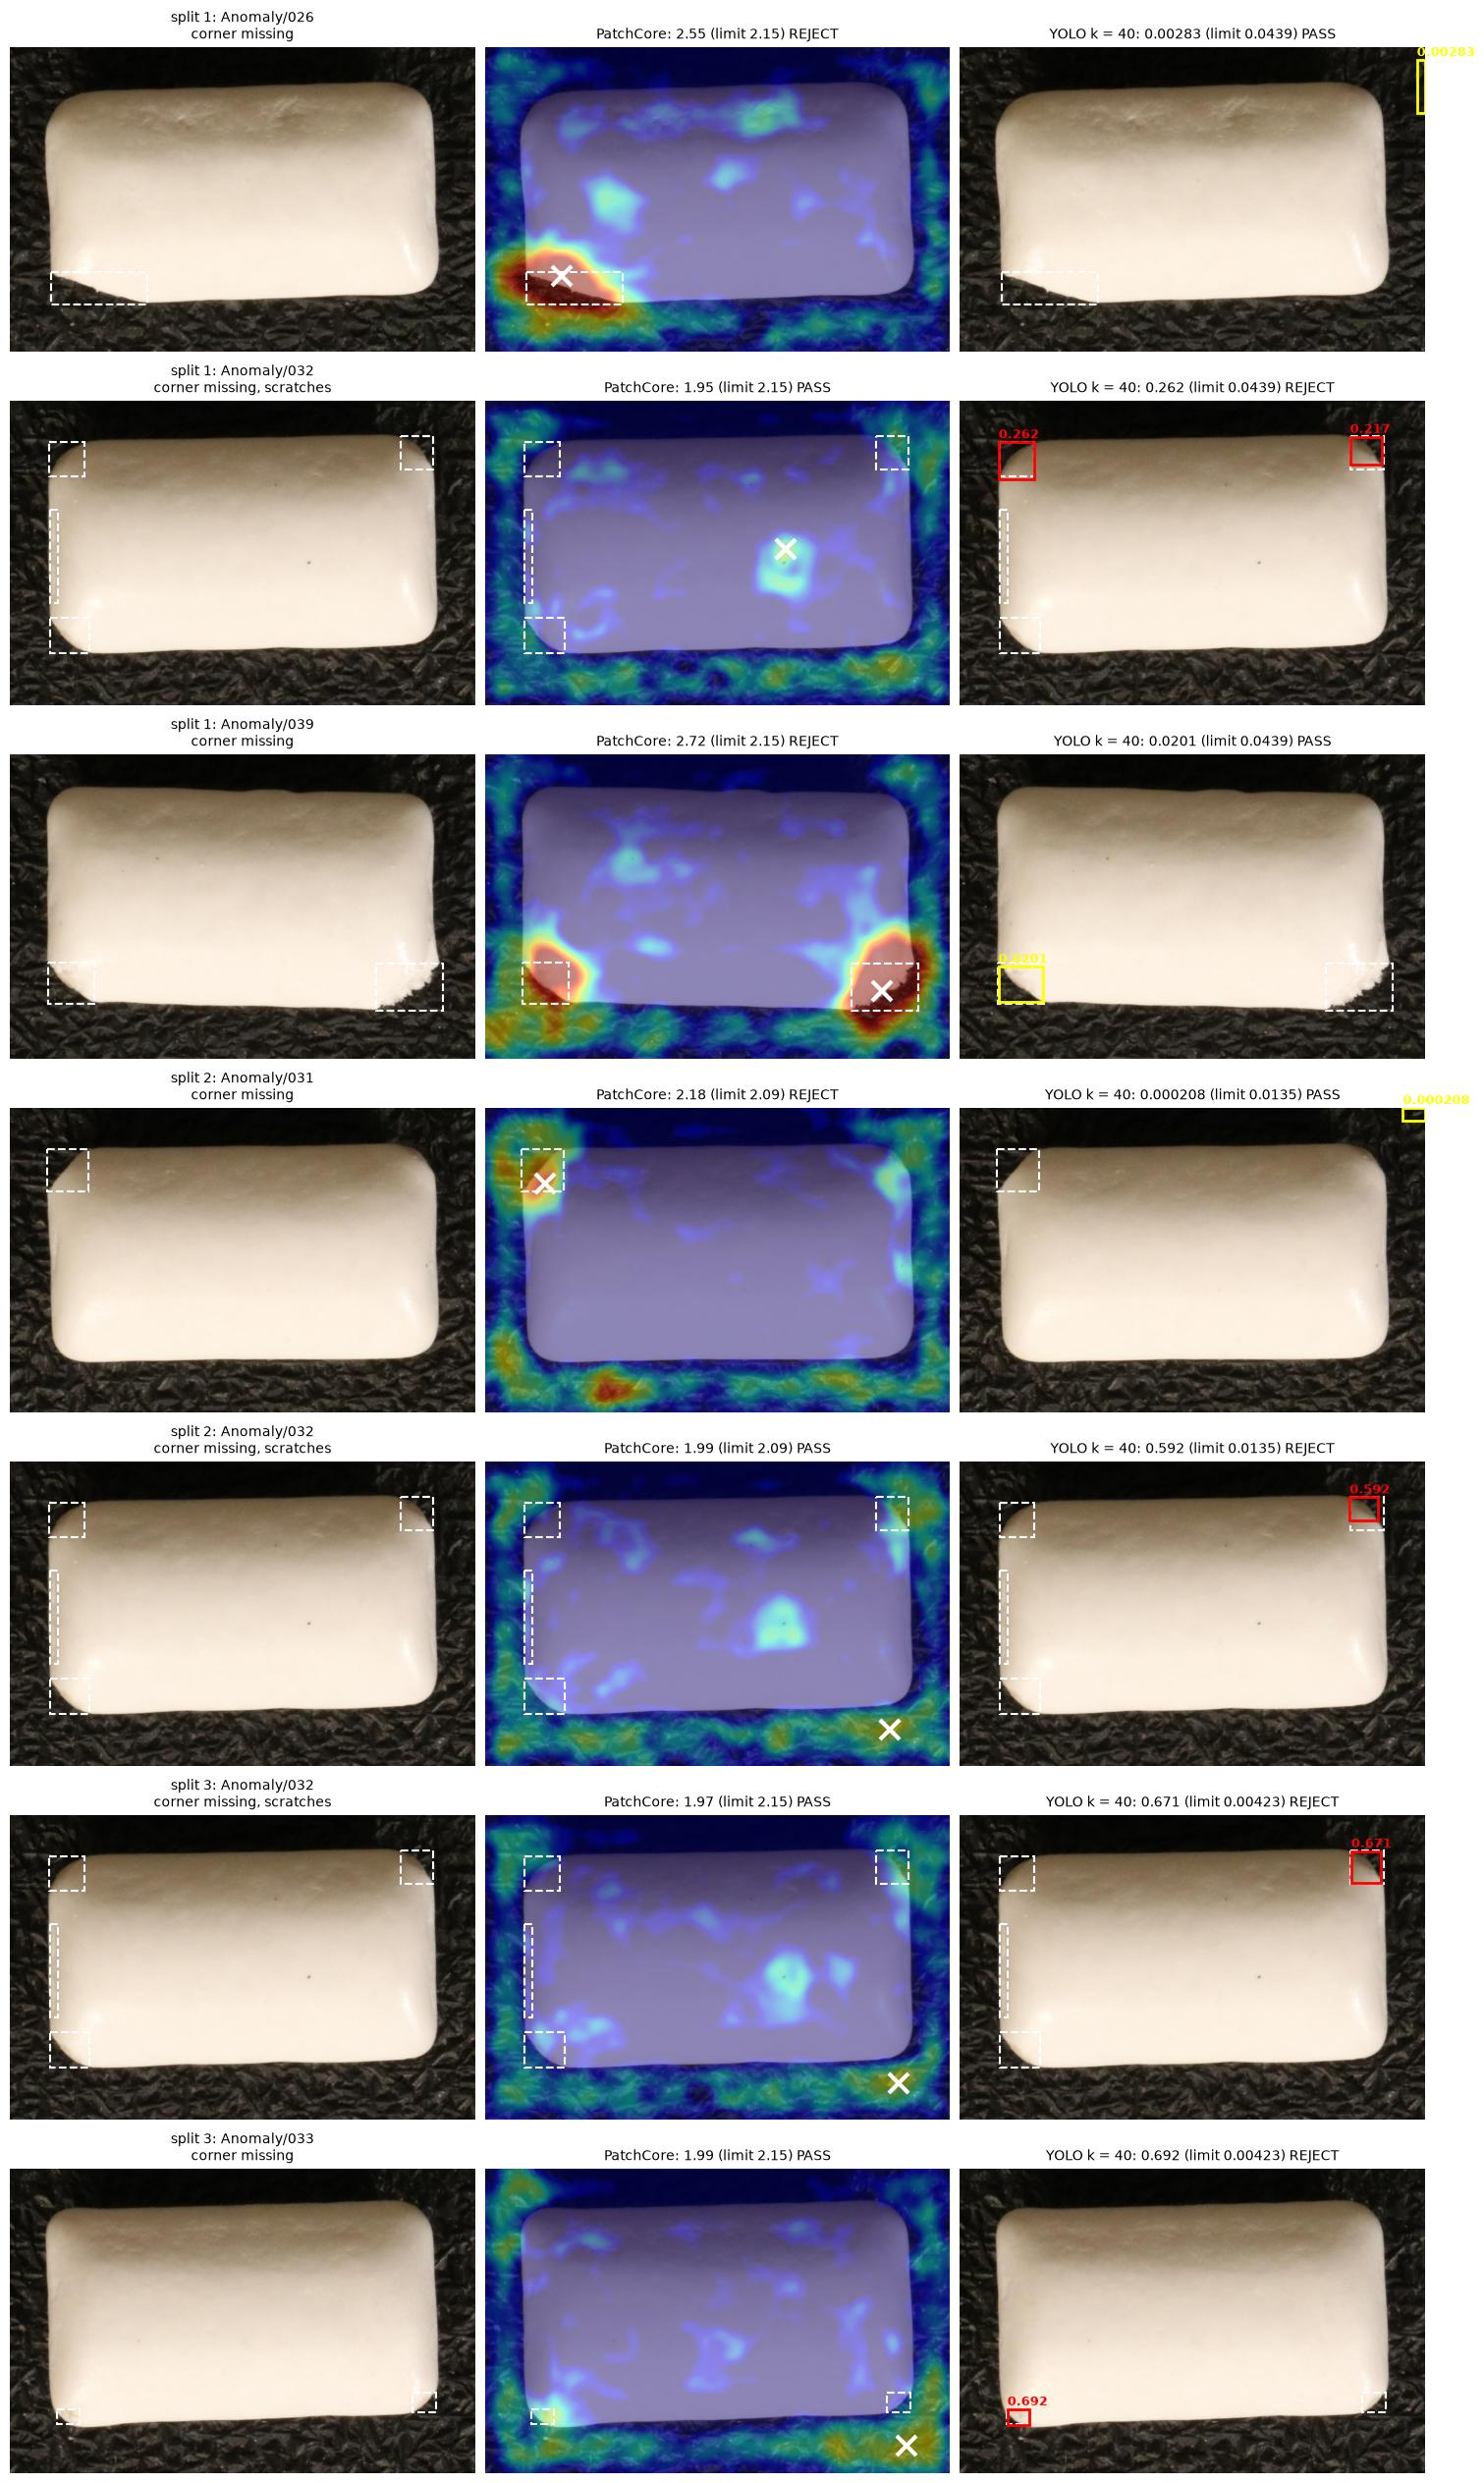

In [17]:
fig, axes = plt.subplots(len(missed), 3, figsize=(15, 3.6 * len(missed)), layout="constrained", squeeze=False)
for ax_row, (s, image) in zip(axes, missed[["split", "image"]].itertuples(index=False)):
    show_photo_row(ax_row, s, image)
plt.show()

> **What we see:** every missed photo has a missing corner (as found in notebook 5.1), but the two models miss different photos.
>
> - **PatchCore misses 2 different photos:** `Anomaly/032`, a test photo in all 3 splits and missed in each of them, and `Anomaly/033`. On both, only tiny pieces are broken off the corners. The heatmap stays blue at those corners, and PatchCore's point lies on the mat or on a small dark dot in the middle of the gum. A tiny missing corner only shows a little more mat, and PatchCore knows mat very well: most of its memory bank is mat (notebook 4.1). This fits the idea from notebook 5.1.
> - **YOLO with k = 40 misses 3 other photos** with bigger missing corners: `Anomaly/026` and `039` (split 1) and `031` (split 2). On 026 and 031 its best box lies on the mat at the edge of the crop, so it did not see the defect. On 039 its best box lies on a missing corner (0.0201), but below the limit (0.0439).
> - **Each model catches the misses of the other:** PatchCore's heatmap is red on the missing corners of 026, 039 and 031, and YOLO puts a box on a broken corner of 032 and 033 (0.262 to 0.692). That is why, at k = 40, every defect test photo is caught by at least one of the two models (notebook 5.1).

## Step 3: Good Photos Rejected by Mistake

### How Many, and Where

> The false rejects of PatchCore and YOLO (`SHOWN_MODEL`) per split, next to the limit of the split. With the same rule, a lower limit means more good photos above it.

In [18]:
false_rejects = decisions[decisions["model"].isin(pair_models) & ~decisions["is_defect"] & decisions["rejected"]].copy()
false_rejects["times the limit"] = false_rejects["score"] / false_rejects["limit"]

limits = pd.read_csv(os.path.join(EVALUATION_DIR, "score_limits.csv"))
per_split = limits[limits["model"].isin(pair_models)][["model", "split", "limit"]].copy()
per_split["false rejects (of 100)"] = [((false_rejects["model"] == model) & (false_rejects["split"] == s)).sum()
                                       for model, s in zip(per_split["model"], per_split["split"])]
per_split

,model,split,limit,false rejects (of 100)
0,PatchCore,1,2.153118,4
4,YOLO k = 40,1,0.043886,2
5,PatchCore,2,2.087670,14
9,YOLO k = 40,2,0.013502,2
10,PatchCore,3,2.149104,2
14,YOLO k = 40,3,0.004233,4


> **What we see:** yes, for both models.
>
> - PatchCore's limit of split 2 (2.09) is the lowest of its three, and it rejects 14 good photos there, against 4 and 2 in the other splits.
> - YOLO's lowest limit is in split 3 (0.00423), with 4 false rejects, against 2 in each of the other splits.
> - So the 14% of PatchCore in notebook 5.1 comes mostly from a limit that came out low, because it was set on only 50 good validation photos.

### The Strongest False Rejects

> For each of the two models, the `FALSE_REJECTS_SHOWN` good photos with the highest score compared with their limit (`times the limit`: the score divided by the limit), and what both models see on them. These photos show what makes good gum look suspicious.

      model  split                                 image  score  limit  times the limit
  PatchCore      3 chewinggum/Data/Images/Normal/353.JPG  2.315  2.149            1.077
  PatchCore      2 chewinggum/Data/Images/Normal/353.JPG  2.244  2.088            1.075
YOLO k = 40      2 chewinggum/Data/Images/Normal/353.JPG  0.683  0.014           50.588
YOLO k = 40      3 chewinggum/Data/Images/Normal/135.JPG  0.185  0.004           43.772


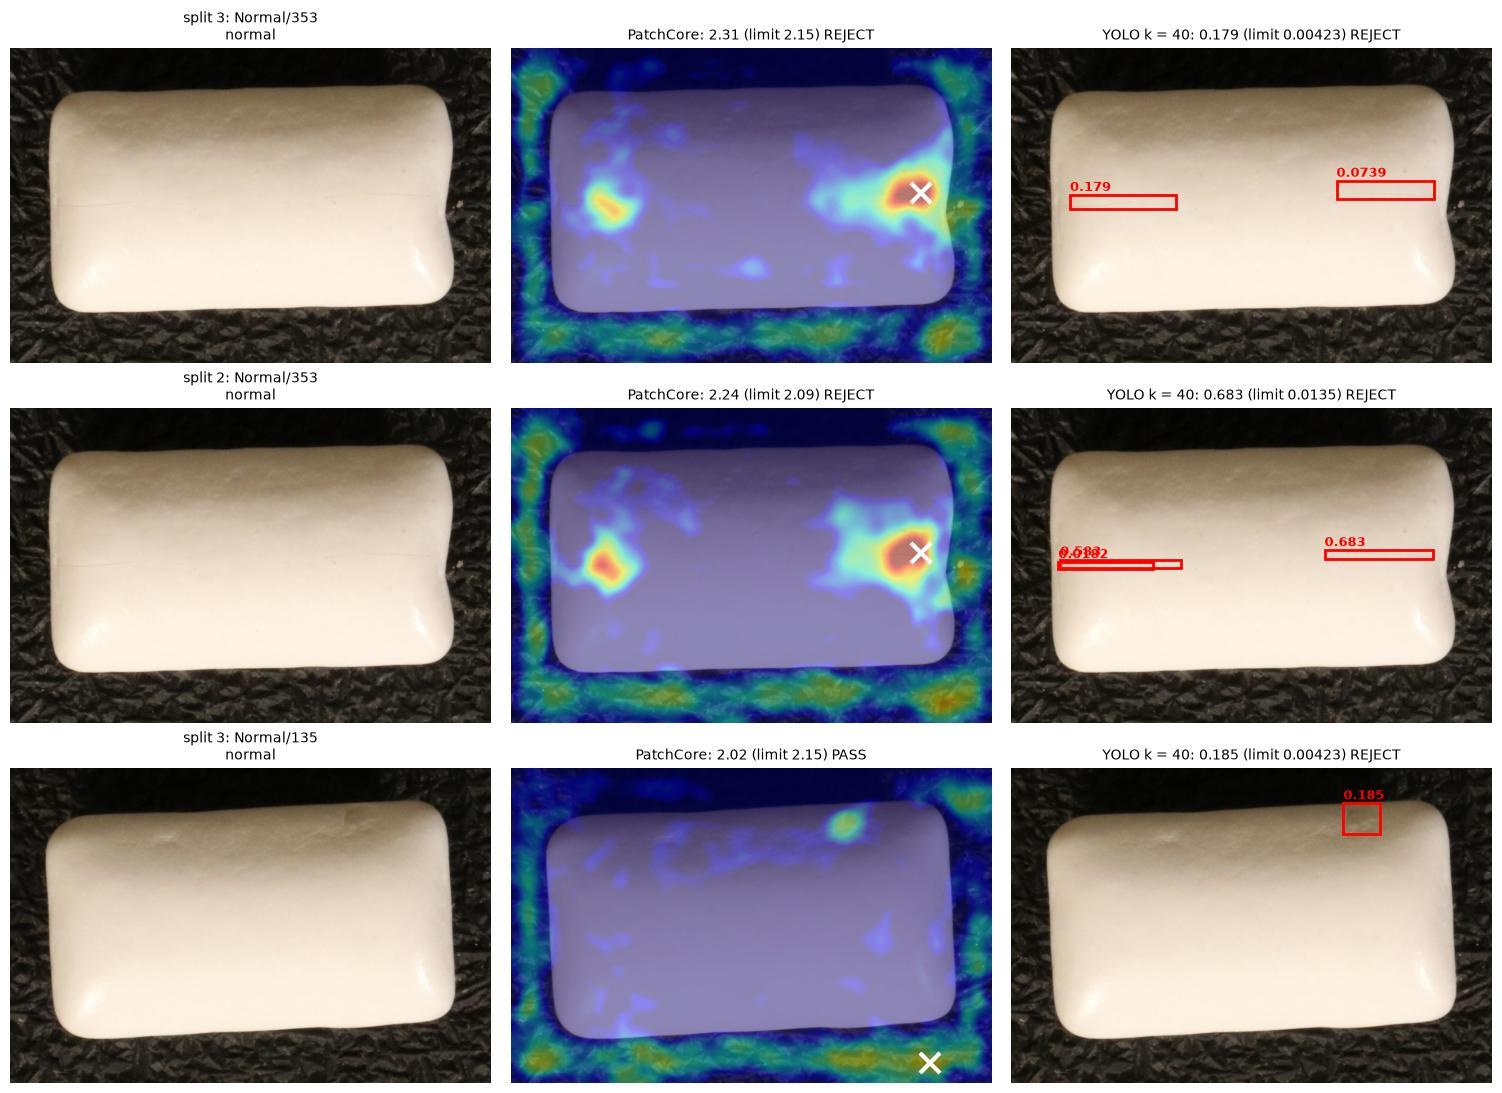

In [19]:
strongest = (false_rejects.sort_values("times the limit", ascending=False).groupby("model").head(FALSE_REJECTS_SHOWN)
             .sort_values(["model", "times the limit"], ascending=[True, False]))
print(strongest[["model", "split", "image", "score", "limit", "times the limit"]].round(3).to_string(index=False))

shown = strongest[["split", "image"]].drop_duplicates()
fig, axes = plt.subplots(len(shown), 3, figsize=(15, 3.6 * len(shown)), layout="constrained", squeeze=False)
for ax_row, (s, image) in zip(axes, shown.itertuples(index=False)):
    show_photo_row(ax_row, s, image)
plt.show()

> **What we see:**
>
> - The strongest false reject of both models is the same good photo, **Normal/353** (a test photo in splits 2 and 3). A thin line runs across the gum, and its right edge has a small dent. PatchCore's two red spots and YOLO's flat red boxes lie on that line, so both models found the same thing, and YOLO treats it like a crack. It may be a small defect that the dataset did not mark, but in our numbers it still counts as a false reject.
> - **Normal/135** (split 3): YOLO reacts to a small dent at the top right of the gum (0.185, far above its low limit of 0.00423). PatchCore gives PASS (2.02), with only a light green spot there.

## Summary

> **What this notebook did**
>
> - For every model and every defect test photo, checked whether the model's most suspicious place lies on the real defect.
> - Drew every missed defect photo of PatchCore and of YOLO with k = 40, with what both models see.
> - Counted the false rejects per split next to the limits, and drew the strongest ones.
>
> Nothing was saved, and the limits and decisions of notebook 5.1 were not changed.
>
> **What we found**
>
> - When a model catches a defect photo, it nearly always points at the real defect: PatchCore in 97.9% of these photos, YOLO in 95.2% to 98.6%.
> - PatchCore misses photos with only tiny pieces broken off the corners (`Anomaly/032` and `033`): there, the photo shows only a little more mat, which looks normal to it. YOLO with k = 40 misses photos with bigger missing corners (`Anomaly/026`, `031` and `039`). Each model catches the misses of the other.
> - The false rejects follow the limit: in each model, the split with the lowest limit has the most false rejects (PatchCore, split 2: 14 of 100).
> - The good photo that both models reject most strongly, `Normal/353`, has a thin line across the gum that both models mark. It may be a defect that the dataset did not mark.
>
> **Next:** the time each model needs per photo.